In [1]:
import pandas as pd
import numpy as np
import glob
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
files = glob.glob("../data/raw/*.csv")

print("CSV files found:", len(files))

if len(files) == 0:
    raise FileNotFoundError(
        "No CSV files found. Put all CIC-IDS2017 CSV files inside data/raw."
    )

dataframes = []

for file in files:
    temp_df = pd.read_csv(file, low_memory=False)
    temp_df.columns = temp_df.columns.str.strip()
    dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)

print("Combined dataset shape:", df.shape)
print(df["Label"].value_counts())

CSV files found: 8
Combined dataset shape: (2830743, 79)
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [3]:
# Replace infinite values with missing values
df = df.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing values
df = df.dropna()

# Convert labels: 0 = Benign, 1 = Attack
df["Label"] = df["Label"].astype(str).str.strip()
df["Label"] = df["Label"].apply(
    lambda label: 0 if label.upper() == "BENIGN" else 1
)

print("Dataset shape after cleaning:", df.shape)
print("\nLabel counts:")
print(df["Label"].value_counts())

Dataset shape after cleaning: (2827876, 79)

Label counts:
Label
0    2271320
1     556556
Name: count, dtype: int64


In [4]:
sample_df = df.sample(
    n=min(100000, len(df)),
    random_state=42
)

X = sample_df.select_dtypes(include="number").drop(
    columns=["Label"], errors="ignore"
)
y = sample_df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("\nTest label counts:")
print(y_test.value_counts())

Training data shape: (80000, 78)
Testing data shape: (20000, 78)

Test label counts:
Label
0    16050
1     3950
Name: count, dtype: int64


In [5]:
import joblib

# Load trained model
model = joblib.load("../models/network_model.joblib")

# Load original test data
X_test = joblib.load("../models/X_test.joblib")
y_test = joblib.load("../models/y_test.joblib")

# Check feature columns
feature_columns = joblib.load("../models/feature_columns.joblib")

X_test = X_test[feature_columns]

print("Model loaded successfully!")
print("Test data shape:", X_test.shape)

Model loaded successfully!
Test data shape: (20000, 78)


In [6]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print("First 10 predictions:", y_pred[:10])

Predictions completed!
First 10 predictions: [0 0 0 0 0 1 0 0 1 1]


In [7]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Accuracy : 0.997
Precision: 0.9964
Recall   : 0.9886
F1-score : 0.9925


In [8]:
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     16050
      Attack       1.00      0.99      0.99      3950

    accuracy                           1.00     20000
   macro avg       1.00      0.99      1.00     20000
weighted avg       1.00      1.00      1.00     20000



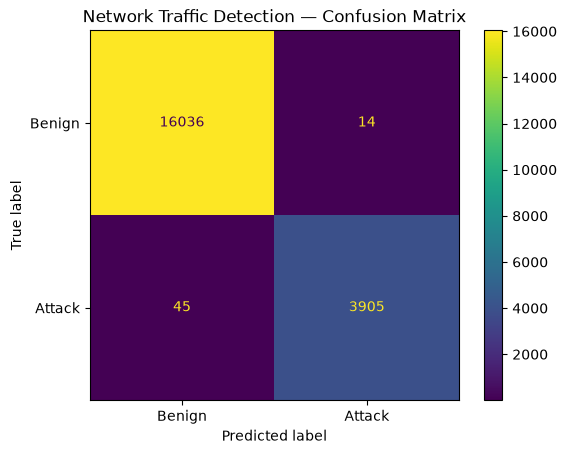

Confusion matrix:
[[16036    14]
 [   45  3905]]


In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Attack"]
)

disp.plot()
plt.title("Network Traffic Detection — Confusion Matrix")
plt.show()

print("Confusion matrix:")
print(cm)

ROC-AUC score: 0.9996


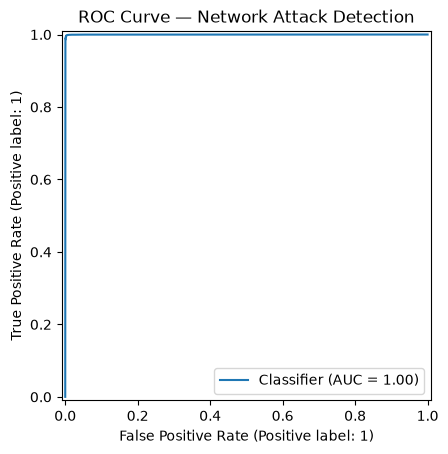

In [10]:
if len(np.unique(y_test)) == 2 and hasattr(model, "predict_proba"):
    y_probability = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_probability)

    print("ROC-AUC score:", round(auc, 4))

    RocCurveDisplay.from_predictions(y_test, y_probability)
    plt.title("ROC Curve — Network Attack Detection")
    plt.show()
else:
    print("ROC-AUC cannot be calculated: both classes or predict_proba are not available.")

In [11]:
import os
import joblib
import pandas as pd

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Create evaluation results
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

# Save evaluation results
results.to_csv("../models/evaluation_results.csv", index=False)

# Save test data and labels
joblib.dump(X_test, "../models/X_test.joblib")
joblib.dump(y_test, "../models/y_test.joblib")

print("Evaluation results saved successfully!")

display(results)

Evaluation results saved successfully!


,Metric,Score
0,Accuracy,0.997050
1,Precision,0.996428
2,Recall,0.988608
3,F1-score,0.992502
